# Título Interesante y Llamativo del Proyecto
## Definición del problema
abc ns ustedes mismos son
## Variables a analizar
### Precipitación:
Los datos recogidos provienen de las siguientes fuentes:
- PISCO: una descripción breve tal vez | Formato: .csv | Forma de acceso: https://figshare.com/articles/dataset/High-resolution_grids_of_rainfall_for_Peru_-_PISCOp_v3_0_dataset/32411886
- climateSERV: acá tmb | Formato: .nc | Forma de acceso
### Cobertura de suelo:
Los datos recogidos provienen de las siguientes fuentes:
- Mapbiomas: acá tmb | Formato: ns | Forma de acceso: ns
- MODIS/061/MCD12Q1: acá tmb | Formato: ns | Forma de acceso: ns
### Enlaces adicionales
- Drive: https://drive.google.com/drive/folders/1gPHBk7qCmcYYvy80GQ7GV8aXXrpXl6pX?usp=sharing
- GitHub: https://github.com/SALINASSebas/geocomp_TF.git

In [ ]:
# Paso 0: Importación de librerías
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xarray as xr

# Exploración preliminar de datos
## Precipitación
### 1. PISCO

In [43]:
# Se llaman los archivos desde la carpeta de Google Drive:
# !pip install gdown -q
import gdown

gdown.download_folder(id='1gPHBk7qCmcYYvy80GQ7GV8aXXrpXl6pX', output='datos_brutos', quiet=False, use_cookies=True)

Retrieving folder contents


Retrieving folder 1mFD0cbvhUxPbqgBpCjBqvouSHBv_LzOT datos_climateSERV
Processing file 1o7Eaw8l0DkdqzfZAwIC8hPyiCFSEA96y README.txt
Processing file 16_D0NsW-YV3hCD3p3_Xxb3yWiQIzKPwv SERV_CHIRPS_1.nc
Processing file 1KmkRM1HjpKMml4zn5b8MtP9KLIn3F_Aa SERV_CHIRPS_2.nc
Processing file 13aHPxEO3p0OugSfzVrB1b2gscysnNExM SERV_CHIRPS_3.nc
Processing file 1PSILew8WN0x0xfomPF-E2ErxsqnNsiai SERV_CHIRPS_4.nc
Retrieving folder 19sYIVFEKuJ4bQMPyodgMRlKW3RVFReuw datos_PISCO
Processing file 1wj-ymOGDYzQfYmoNHZ8Hmb81RN3PaxVL PISCOp_m.nc
Processing file 1n-KhItYZTEa1XbZqp-xTwHe0sFaB35TB README.txt
Retrieving folder 1oL_1bbvLptq-lKKH1SxiXdmkKgFQIHrZ SHAPEFILES
Processing file 1e0lrb5p6d8fYhCY4e8YR7jdhGgJFskbj bofAntauta.gpkg
Processing file 1-OJUBDYp6VOwOTApYpBz9tjjGBFziXbd bofCaplina.gpkg
Processing file 1gSo_wx6wtJjFDL7BWqT9_H2Xu-vG3xXl SHAPEFILES_bof-20261015T211729Z-1-001.zip
Processing file 1pIQT-bNbn8PFl8yp3KyyUVQ6JDh5yJyC UniHidroMen_ANA_geogpsperu.zip


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1o7Eaw8l0DkdqzfZAwIC8hPyiCFSEA96y
To: /home/sebas/GitHub/geocomp_TF/datos_brutos/datos_climateSERV/README.txt
100%|██████████| 308/308 [00:00<00:00, 190kB/s]
Downloading...
From: https://drive.google.com/uc?id=16_D0NsW-YV3hCD3p3_Xxb3yWiQIzKPwv
To: /home/sebas/GitHub/geocomp_TF/datos_brutos/datos_climateSERV/SERV_CHIRPS_1.nc
100%|██████████| 251k/251k [00:00<00:00, 1.49MB/s]
Downloading...
From: https://drive.google.com/uc?id=1KmkRM1HjpKMml4zn5b8MtP9KLIn3F_Aa
To: /home/sebas/GitHub/geocomp_TF/datos_brutos/datos_climateSERV/SERV_CHIRPS_2.nc
100%|██████████| 211k/211k [00:00<00:00, 1.32MB/s]
Downloading...
From: https://drive.google.com/uc?id=13aHPxEO3p0OugSfzVrB1b2gscysnNExM
To: /home/sebas/GitHub/geocomp_TF/datos_brutos/datos_climateSERV/SERV_CHIRPS_3.nc
100%|██████████| 211k/211k [00:00<00:00, 1.42MB/s]
Downloading...
From: https:/

['datos_brutos/datos_climateSERV/README.txt',
 'datos_brutos/datos_climateSERV/SERV_CHIRPS_1.nc',
 'datos_brutos/datos_climateSERV/SERV_CHIRPS_2.nc',
 'datos_brutos/datos_climateSERV/SERV_CHIRPS_3.nc',
 'datos_brutos/datos_climateSERV/SERV_CHIRPS_4.nc',
 'datos_brutos/datos_PISCO/PISCOp_m.nc',
 'datos_brutos/datos_PISCO/README.txt',
 'datos_brutos/SHAPEFILES/bofAntauta.gpkg',
 'datos_brutos/SHAPEFILES/bofCaplina.gpkg',
 'datos_brutos/SHAPEFILES/SHAPEFILES_bof-20261015T211729Z-1-001.zip',
 'datos_brutos/SHAPEFILES/UniHidroMen_ANA_geogpsperu.zip']

In [51]:
ruta = '/home/sebas/GitHub/geocomp_TF/datos_brutos/datos_PISCO/'
archivo = 'PISCOp_m.nc'

pisco = xr.open_dataset(ruta+archivo)
pisco

<xarray.Dataset> Size: 79MB
Dimensions:        (Z1: 540, latitude: 210, longitude: 174)
Coordinates:
  * Z1             (Z1) int32 2kB 1 2 3 4 5 6 7 ... 534 535 536 537 538 539 540
  * latitude       (latitude) float64 2kB 1.95 1.85 1.75 ... -18.85 -18.95
  * longitude      (longitude) float64 1kB -81.35 -81.25 ... -64.15 -64.05
Data variables:
    precipitation  (Z1, latitude, longitude) float32 79MB ...
    crs            int32 4B ...
Attributes:
    Conventions:   CF-1.4
    created_by:    R packages ncdf4 and terra (version 1.8-70)
    created_date:  2026-05-26 18:28:02

In [52]:
# La data recopila datos mensuales promedio de precipitación en un rango de 1981-2025. Se debe seleccionar los meses correspondientes a los años de interés:
ini = '1981-1-1'
fin = '2025-12-1'
fecha = pd.date_range(ini,fin, freq='MS')#.to_period('M')

# Se asigna las nuevas coordenadas y se renombra la dimensión Z1
rname = {'Z1':'time'}
pisco_date = pisco.assign_coords(Z1=fecha).rename(rname)

# Se selecciona los meses correspondientes al rango de fechas de interés para la variable de precipitación
pisco_p = pisco_date['precipitation'].sel(time=slice('2000-1-1','2024-12-1'))
pisco_p

<xarray.DataArray 'precipitation' (time: 300, latitude: 210, longitude: 174)> Size: 44MB
[10962000 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[us] 2kB 2000-01-01 2000-02-01 ... 2024-12-01
  * latitude   (latitude) float64 2kB 1.95 1.85 1.75 ... -18.75 -18.85 -18.95
  * longitude  (longitude) float64 1kB -81.35 -81.25 -81.15 ... -64.15 -64.05
Attributes:
    units:         mm
    long_name:     PISCOp_v3.0: Gridded rainfall dataset for Peru from 1981 t...
    grid_mapping:  crs

In [5]:
# Se definen los límites espaciales de interés en base a la información geográfica de los bofedales
# Primero, se carga la data de los geopackages respectivos
ruta1 = '/home/sebas/GitHub/geocomp_TF/datos_brutos/SHAPEFILES/'

bof_antauta = gpd.read_file(ruta1+'bofAntauta.gpkg')
bof_caplina = gpd.read_file(ruta1+'bofCaplina.gpkg')

In [59]:
# Se selecciona la data mínima y máxima de las latitudes y longitudes de los bofedales
def georecorte(xarr: xr.DataArray, geodf: gpd.GeoDataFrame, buffer: float=0) -> xr.DataArray:
    """Devuelve el DataArray recortado en la extensión espacial de la data georreferenciada"""
    min_x = float(geodf.total_bounds[0])-buffer # El valor sumado o restado aumenta el tamaño del recorte
    min_y = float(geodf.total_bounds[1])-buffer
    max_x = float(geodf.total_bounds[2])+buffer
    max_y = float(geodf.total_bounds[3])+buffer
    return xarr.sel(latitude=slice(max_y,min_y), longitude=slice(min_x,max_x))

p_antauta = georecorte(pisco_p, bof_antauta, .3)
p_caplina = georecorte(pisco_p, bof_caplina, .3)

In [60]:
# Visualización de datos recortados
p_antauta

<xarray.DataArray 'precipitation' (time: 300, latitude: 7, longitude: 7)> Size: 59kB
[14700 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[us] 2kB 2000-01-01 2000-02-01 ... 2024-12-01
  * latitude   (latitude) float64 56B -13.95 -14.05 -14.15 ... -14.45 -14.55
  * longitude  (longitude) float64 56B -70.65 -70.55 -70.45 ... -70.15 -70.05
Attributes:
    units:         mm
    long_name:     PISCOp_v3.0: Gridded rainfall dataset for Peru from 1981 t...
    grid_mapping:  crs

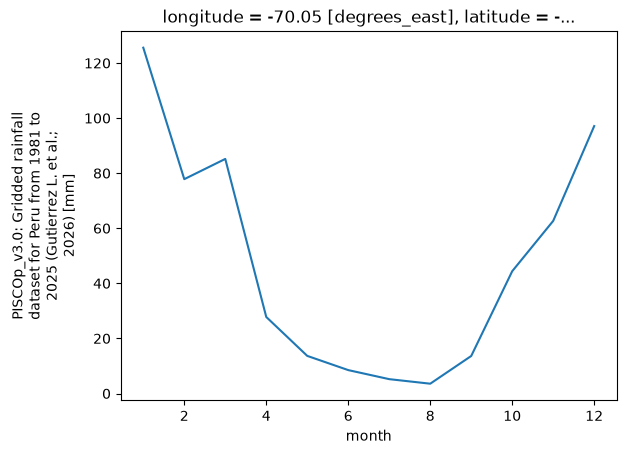

In [56]:
# Visualización de datos como promedio anual para una coordenada específica
punto = p_antauta.sel(latitude=-14, longitude=-70, method='nearest')

punto.groupby('time.month').mean(dim='time').plot(x='month')

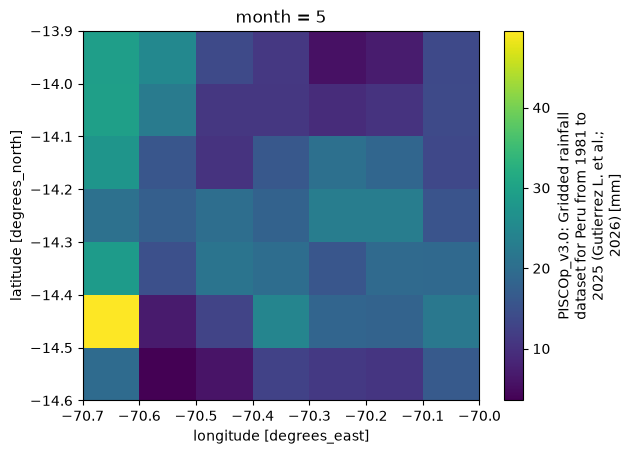

In [ ]:
# Visualización de la precipitación promedio del área de interés en junio
p_antauta.groupby('time.month').mean().sel(month=5).plot()

In [68]:
# Visualización de la región recortada

p_antauta.groupby('time.month').plot()

AttributeError: 'DataArrayGroupBy' object has no attribute 'plot'

### 2. climateSERV

## Cobertura de suelo
### 1. MapBiomas

### 2. MODIS/061/MCD12Q1